In [1]:
import pandas as pd 
import numpy as np 

In [2]:
df=pd.read_csv("train.csv")
cdf=df.copy()

In [3]:
cdf.shape

(891, 12)

In [4]:
cdf.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
cdf.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
68,69,1,3,"Andersson, Miss. Erna Alexandra",female,17.0,4,2,3101281,7.9250,NaN,S
225,226,0,3,"Berglund, Mr. Karl Ivar Sven",male,22.0,0,0,PP 4348,9.3500,NaN,S
137,138,0,1,"Futrelle, Mr. Jacques Heath",male,37.0,1,0,113803,53.1000,C123,S
100,101,0,3,"Petranec, Miss. Matilda",female,28.0,0,0,349245,7.8958,NaN,S
751,752,1,3,"Moor, Master. Meier",male,6.0,0,1,392096,12.4750,E121,S


In [6]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
cdf.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
cdf.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
missing_precentage=((cdf.isna().sum())/(len(cdf)))*100 

In [10]:
res=pd.DataFrame({'missing':missing_precentage})
res

,missing
PassengerId,0.000000
Survived,0.000000
Pclass,0.000000
Name,0.000000
Sex,0.000000
Age,19.865320
SibSp,0.000000
Parch,0.000000
Ticket,0.000000
Fare,0.000000


In [11]:
print("Duplicated value Counts :",cdf.duplicated().sum())
print("Duplicate Passenger Ids Counts :",cdf.PassengerId.duplicated().sum())
print("Survived Distribution",cdf.Survived.value_counts())

Duplicated value Counts : 0
Duplicate Passenger Ids Counts : 0
Survived Distribution Survived
0    549
1    342
Name: count, dtype: int64


In [12]:
cdf.Age.unique()

array([22.  , 38.  , 26.  , 35.  ,   nan, 54.  ,  2.  , 27.  , 14.  ,
        4.  , 58.  , 20.  , 39.  , 55.  , 31.  , 34.  , 15.  , 28.  ,
        8.  , 19.  , 40.  , 66.  , 42.  , 21.  , 18.  ,  3.  ,  7.  ,
       49.  , 29.  , 65.  , 28.5 ,  5.  , 11.  , 45.  , 17.  , 32.  ,
       16.  , 25.  ,  0.83, 30.  , 33.  , 23.  , 24.  , 46.  , 59.  ,
       71.  , 37.  , 47.  , 14.5 , 70.5 , 32.5 , 12.  ,  9.  , 36.5 ,
       51.  , 55.5 , 40.5 , 44.  ,  1.  , 61.  , 56.  , 50.  , 36.  ,
       45.5 , 20.5 , 62.  , 41.  , 52.  , 63.  , 23.5 ,  0.92, 43.  ,
       60.  , 10.  , 64.  , 13.  , 48.  ,  0.75, 53.  , 57.  , 80.  ,
       70.  , 24.5 ,  6.  ,  0.67, 30.5 ,  0.42, 34.5 , 74.  ])

In [13]:
cdf.Age.isna().sum()

np.int64(177)

In [14]:
cdf['Age']=cdf['Age'].fillna(cdf.Age.mean())
cdf.Age.isna().sum()

np.int64(0)

In [15]:
cdf.Sex.unique()



array(['male', 'female'], dtype=object)

In [16]:
cdf['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [17]:
cdf[cdf['Fare']<=0]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
179,180,0,3,"Leonard, Mr. Lionel",male,36.000000,0,0,LINE,0.0,NaN,S
263,264,0,1,"Harrison, Mr. William",male,40.000000,0,0,112059,0.0,B94,S
271,272,1,3,"Tornquist, Mr. William Henry",male,25.000000,0,0,LINE,0.0,NaN,S
277,278,0,2,"Parkes, Mr. Francis ""Frank""",male,29.699118,0,0,239853,0.0,NaN,S
302,303,0,3,"Johnson, Mr. William Cahoone Jr",male,19.000000,0,0,LINE,0.0,NaN,S
413,414,0,2,"Cunningham, Mr. Alfred Fleming",male,29.699118,0,0,239853,0.0,NaN,S
466,467,0,2,"Campbell, Mr. William",male,29.699118,0,0,239853,0.0,NaN,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,29.699118,0,0,239854,0.0,NaN,S
597,598,0,3,"Johnson, Mr. Alfred",male,49.000000,0,0,LINE,0.0,NaN,S
633,634,0,1,"Parr, Mr. William Henry Marsh",male,29.699118,0,0,112052,0.0,NaN,S


In [18]:
fare=(np.where([cdf['Fare']<=0]))


In [19]:
cdf=cdf.drop(['Cabin','Ticket','PassengerId','Name'],axis=1)

In [20]:
cdf.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [21]:
cdf.Embarked.unique()

array(['S', 'C', 'Q', nan], dtype=object)

In [22]:
cdf.Embarked.isna().sum()

np.int64(2)

In [23]:
cdf['Embarked']=cdf.Embarked.fillna(cdf.Embarked.mode())

In [24]:
cdf.isna().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    2
dtype: int64

In [25]:
from sklearn.preprocessing import OneHotEncoder

OHE=OneHotEncoder(
    sparse_output=False
)
encode=OHE.fit_transform(cdf[['Embarked']])

In [26]:

Cat_encoded_df=pd.DataFrame(
    encode,
    columns=OHE.get_feature_names_out(['Embarked']),
    index=cdf.index
)


In [27]:
Cat_encoded_df

,Embarked_C,Embarked_Q,Embarked_S,Embarked_nan
0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0
...,...,...,...,...
886,0.0,0.0,1.0,0.0
887,0.0,0.0,1.0,0.0
888,0.0,0.0,1.0,0.0
889,1.0,0.0,0.0,0.0


In [28]:
cdf=cdf.drop(columns=['Embarked'])
cdf=pd.concat([cdf,Cat_encoded_df],axis=1)

In [29]:
cdf=cdf.drop(['Embarked_nan'],axis=1)

In [30]:
from sklearn.preprocessing import LabelEncoder
Le=LabelEncoder()
cdf['Sex']=Le.fit_transform(cdf[['Sex']])

c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [31]:
cdf.Sex.replace({
    
})

0      1
1      0
2      0
3      0
4      1
      ..
886    1
887    0
888    0
889    1
890    1
Name: Sex, Length: 891, dtype: int64

In [32]:
cdf

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,22.000000,1,0,7.2500,0.0,0.0,1.0
1,1,1,0,38.000000,1,0,71.2833,1.0,0.0,0.0
2,1,3,0,26.000000,0,0,7.9250,0.0,0.0,1.0
3,1,1,0,35.000000,1,0,53.1000,0.0,0.0,1.0
4,0,3,1,35.000000,0,0,8.0500,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
886,0,2,1,27.000000,0,0,13.0000,0.0,0.0,1.0
887,1,1,0,19.000000,0,0,30.0000,0.0,0.0,1.0
888,0,3,0,29.699118,1,2,23.4500,0.0,0.0,1.0
889,1,1,1,26.000000,0,0,30.0000,1.0,0.0,0.0


In [33]:
correlation=cdf.corr(numeric_only=True)

In [34]:
correlation

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
Survived,1.000000,-0.338481,-0.543351,-0.069809,-0.035322,0.081629,0.257307,0.168240,0.003650,-0.155660
Pclass,-0.338481,1.000000,0.131900,-0.331339,0.083081,0.018443,-0.549500,-0.243292,0.221009,0.081720
Sex,-0.543351,0.131900,1.000000,0.084153,-0.114631,-0.245489,-0.182333,-0.082853,-0.074115,0.125722
Age,-0.069809,-0.331339,0.084153,1.000000,-0.232625,-0.179191,0.091566,0.032024,-0.013855,-0.027121
SibSp,-0.035322,0.083081,-0.114631,-0.232625,1.000000,0.414838,0.159651,-0.059528,-0.026354,0.070941
Parch,0.081629,0.018443,-0.245489,-0.179191,0.414838,1.000000,0.216225,-0.011069,-0.081228,0.063036
Fare,0.257307,-0.549500,-0.182333,0.091566,0.159651,0.216225,1.000000,0.269335,-0.117216,-0.166603
Embarked_C,0.168240,-0.243292,-0.082853,0.032024,-0.059528,-0.011069,0.269335,1.000000,-0.148258,-0.778359
Embarked_Q,0.003650,0.221009,-0.074115,-0.013855,-0.026354,-0.081228,-0.117216,-0.148258,1.000000,-0.496624
Embarked_S,-0.155660,0.081720,0.125722,-0.027121,0.070941,0.063036,-0.166603,-0.778359,-0.496624,1.000000


***EDA***

1)Plot counts of Survived classes.

<Axes: xlabel='Survived', ylabel='count'>

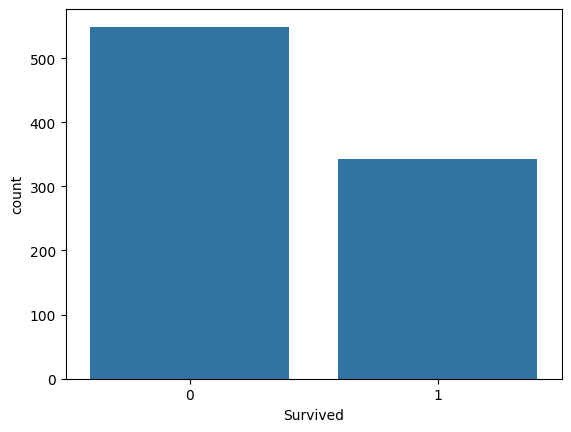

In [35]:
import seaborn as sns
sns.countplot(data=cdf,x='Survived')

<Axes: xlabel='Pclass', ylabel='Survived'>

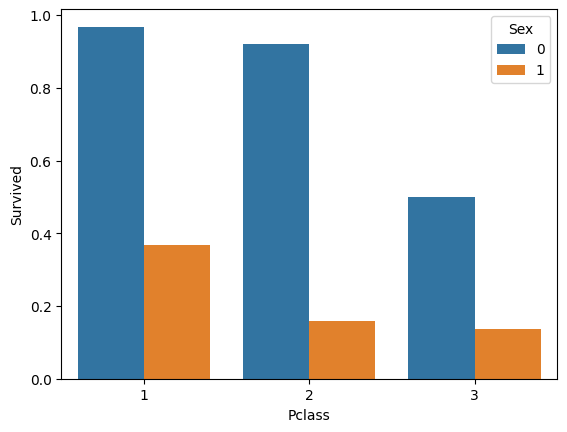

In [36]:
sns.barplot(data=cdf,x='Pclass',y='Survived',hue='Sex',errorbar=None)

<Axes: xlabel='Age', ylabel='Count'>

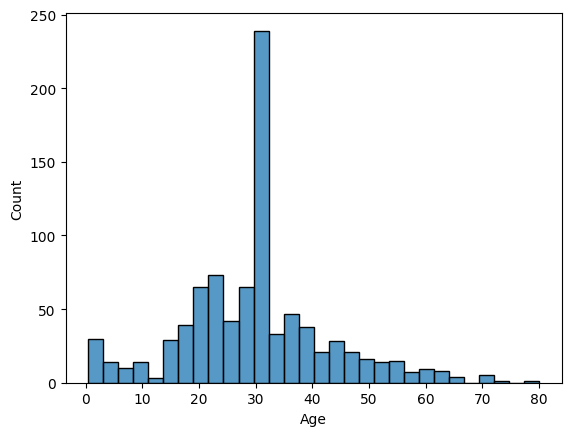

In [37]:
sns.histplot(data=cdf,x='Age')

<Axes: xlabel='Survived', ylabel='Age'>

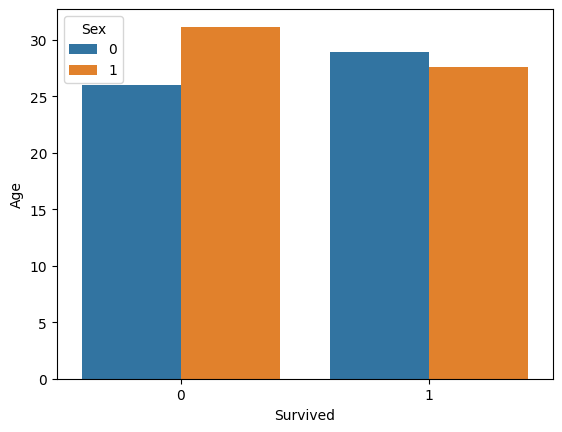

In [38]:
sns.barplot(data=cdf,y='Age',x='Survived',hue='Sex',errorbar=None)

<Axes: xlabel='Fare', ylabel='Count'>

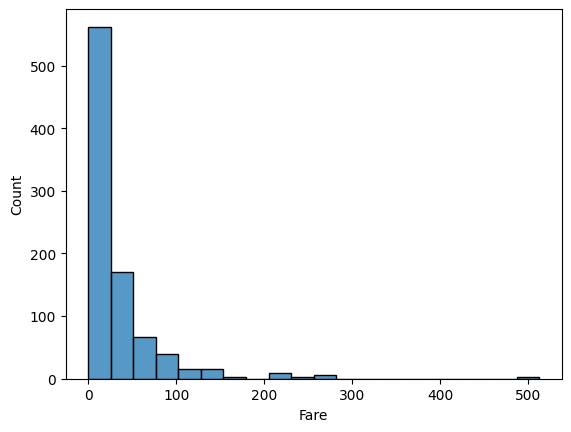

In [39]:
sns.histplot(data=cdf,x='Fare',bins=20)

In [40]:
cdf

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,22.000000,1,0,7.2500,0.0,0.0,1.0
1,1,1,0,38.000000,1,0,71.2833,1.0,0.0,0.0
2,1,3,0,26.000000,0,0,7.9250,0.0,0.0,1.0
3,1,1,0,35.000000,1,0,53.1000,0.0,0.0,1.0
4,0,3,1,35.000000,0,0,8.0500,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
886,0,2,1,27.000000,0,0,13.0000,0.0,0.0,1.0
887,1,1,0,19.000000,0,0,30.0000,0.0,0.0,1.0
888,0,3,0,29.699118,1,2,23.4500,0.0,0.0,1.0
889,1,1,1,26.000000,0,0,30.0000,1.0,0.0,0.0


***MODEL TRAINING***

In [41]:
X=cdf.drop(['Survived'],axis=1)
Y=cdf.Survived

In [42]:
from sklearn.model_selection import train_test_split


In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.20,stratify=Y,random_state=42)
scalar=StandardScaler()

x_train_scaled=scalar.fit_transform(x_train)
x_test_scaled=scalar.transform(x_test)

logis_reg=LogisticRegression()
logis_reg.fit(x_train_scaled,y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [44]:
y_pred=logis_reg.predict(x_test_scaled)

In [45]:
from sklearn.metrics import f1_score,classification_report,confusion_matrix
from sklearn.metrics import accuracy_score
print('F1_score :',f1_score(y_test,y_pred))
print('Accuracy score :',accuracy_score(y_test,y_pred))
print('Classification report ')
print(classification_report(y_test,y_pred))
print("----"*20)
print("Confusion Matrix")
print(confusion_matrix(y_test,y_pred))

F1_score : 0.7244094488188977
Accuracy score : 0.8044692737430168
Classification report 
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

--------------------------------------------------------------------------------
Confusion Matrix
[[98 12]
 [23 46]]


In [46]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

def logi_model():
    return Pipeline([
        ('scaler',StandardScaler()),
        ('Logi_reg',LogisticRegression(random_state=22))
    ])

mods=logi_model()
param_grid={
    'Logi_reg__random_state':[42]
}
grid=GridSearchCV(
    estimator=mods,
    param_grid=param_grid,
    cv=5,
    scoring='f1'
)

grid.fit(x_train,y_train)


,estimator,Pipeline(step...m_state=22))])
,param_grid,{'Logi_reg__random_state': [42]}
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [47]:
best_model=grid.best_estimator_
print("Best Model :",best_model)
print("\n")
print("Best Param :",grid.best_params_)
print("Best CV Score :",grid.best_score_)

Best Model : Pipeline(steps=[('scaler', StandardScaler()),
                ('Logi_reg', LogisticRegression(random_state=42))])


Best Param : {'Logi_reg__random_state': 42}
Best CV Score : 0.7241197247288305


***KNN - K-NEAREST NEIGHBOR***

In [48]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=4)
knn.fit(x_train_scaled,y_train)

,n_neighbors,4
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [49]:
y_pred_knn=knn.predict(x_test_scaled)

In [50]:
from sklearn.metrics import f1_score,classification_report,confusion_matrix
from sklearn.metrics import accuracy_score
print('F1_score :',f1_score(y_test,y_pred_knn))
print('Accuracy score :',accuracy_score(y_test,y_pred_knn))
print('Classification report ')
print(classification_report(y_test,y_pred_knn))
print("----"*20)
print("Confusion Matrix")
print(confusion_matrix(y_test,y_pred_knn))

F1_score : 0.7213114754098361
Accuracy score : 0.8100558659217877
Classification report 
              precision    recall  f1-score   support

           0       0.80      0.92      0.86       110
           1       0.83      0.64      0.72        69

    accuracy                           0.81       179
   macro avg       0.82      0.78      0.79       179
weighted avg       0.81      0.81      0.80       179

--------------------------------------------------------------------------------
Confusion Matrix
[[101   9]
 [ 25  44]]


In [51]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

def knn_model(neighbors):
    return Pipeline([
        ('scaler',StandardScaler()),
        ('knn',KNeighborsClassifier(n_neighbors=neighbors))
    ])

mods=knn_model(neighbors=1)
param_grid={
    'knn__n_neighbors':list(range(1,12))
}
grid=GridSearchCV(
    estimator=mods,
    param_grid=param_grid,
    cv=5,
    scoring='f1'
)

grid.fit(x_train,y_train)


,estimator,Pipeline(step...eighbors=1))])
,param_grid,"{'knn__n_neighbors': [1, 2, ...]}"
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [52]:
best_model=grid.best_estimator_
print("Best Model :",best_model)
print("\n")
print("Best Param :",grid.best_params_)
print("Best CV Score :",grid.best_score_)

Best Model : Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(n_neighbors=3))])


Best Param : {'knn__n_neighbors': 3}
Best CV Score : 0.7422757962712679


***Decision Tree***

In [72]:
from sklearn.tree import DecisionTreeClassifier
tree=DecisionTreeClassifier(max_depth=1,random_state=42)
tree.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [73]:
y_pred_tree=tree.predict(x_test)

In [74]:
from sklearn.metrics import f1_score,classification_report,confusion_matrix
from sklearn.metrics import accuracy_score
print('F1_score :',f1_score(y_test,y_pred_tree))
print('Accuracy score :',accuracy_score(y_test,y_pred_tree))
print('Classification report ')
print(classification_report(y_test,y_pred_tree))
print("----"*20)
print("Confusion Matrix")
print(confusion_matrix(y_test,y_pred_tree))

F1_score : 0.6923076923076923
Accuracy score : 0.776536312849162
Classification report 
              precision    recall  f1-score   support

           0       0.80      0.85      0.82       110
           1       0.74      0.65      0.69        69

    accuracy                           0.78       179
   macro avg       0.77      0.75      0.76       179
weighted avg       0.77      0.78      0.77       179

--------------------------------------------------------------------------------
Confusion Matrix
[[94 16]
 [24 45]]


In [75]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

def Decision_model(depth):
    return Pipeline([
        ('Decision',DecisionTreeClassifier(max_depth=depth))
    ])

mods=Decision_model(depth=1)
param_grid={
    'Decision__max_depth':list(range(1,15))
}
grid=GridSearchCV(
    estimator=mods,
    param_grid=param_grid,
    cv=5,
    scoring='f1'
)

grid.fit(x_train,y_train)


,estimator,Pipeline(step...ax_depth=1))])
,param_grid,"{'Decision__max_depth': [1, 2, ...]}"
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [76]:
y_pred_Decision=grid.predict(x_test)

In [77]:
best_model=grid.best_estimator_
print("Best Model :",best_model)
print("\n")
print("Best Param :",grid.best_params_)
print("Best CV Score :",grid.best_score_)

Best Model : Pipeline(steps=[('Decision', DecisionTreeClassifier(max_depth=9))])


Best Param : {'Decision__max_depth': 9}
Best CV Score : 0.7391655733403306


***RANDOM FOREST***

In [78]:
from sklearn.ensemble import RandomForestClassifier

R_F_model=RandomForestClassifier(max_depth=3,n_estimators=50)
R_F_model.fit(x_train,y_train)


,n_estimators,50
,criterion,'gini'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
y_pred_RDF=R_F_model.predict(x_test)

In [ ]:
from sklearn.metrics import f1_score,classification_report,confusion_matrix
from sklearn.metrics import accuracy_score
print('F1_score :',f1_score(y_test,y_pred_RDF))
print('Accuracy score :',accuracy_score(y_test,y_pred_RDF))
print('Classification report ')
print(classification_report(y_test,y_pred_RDF))
print("----"*20)
print("Confusion Matrix")
print(confusion_matrix(y_test,y_pred_RDF))

F1_score : 0.7333333333333333
Accuracy score : 0.8212290502793296
Classification report 
              precision    recall  f1-score   support

           0       0.80      0.94      0.87       110
           1       0.86      0.64      0.73        69

    accuracy                           0.82       179
   macro avg       0.83      0.79      0.80       179
weighted avg       0.83      0.82      0.81       179

--------------------------------------------------------------------------------
Confusion Matrix
[[103   7]
 [ 25  44]]


***RANDOM FORSET USING GRID SEARCH CV***

In [79]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

def random_model(depth):
    return Pipeline([
        ('Random',RandomForestClassifier(max_depth=depth))
    ])

mods=random_model(depth=1)
param_grid={
    'Random__max_depth':list(range(1,15)),
    'Random__n_estimators':[100,150,None],
}

grid=GridSearchCV(
    estimator=mods,
    param_grid=param_grid,
    cv=5,
    scoring='f1'
)

grid.fit(x_train,y_train)


c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
70 fits failed out of a total of 210.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
70 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Pawan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\Pawan\AppDa

,estimator,Pipeline(step...ax_depth=1))])
,param_grid,"{'Random__max_depth': [1, 2, ...], 'Random__n_estimators': [100, 150, ...]}"
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,150


In [80]:
y_pred_Random_forest=grid.predict(x_test)

In [82]:
from sklearn.metrics import f1_score,classification_report,confusion_matrix
from sklearn.metrics import accuracy_score
print('F1_score :',f1_score(y_test,y_pred_Random_forest))
print('Accuracy score :',accuracy_score(y_test,y_pred_Random_forest))
print('Classification report ')
print(classification_report(y_test,y_pred_Random_forest))
print("----"*20)
print("Confusion Matrix")
print(confusion_matrix(y_test,y_pred_Random_forest))

F1_score : 0.7049180327868853
Accuracy score : 0.7988826815642458
Classification report 
              precision    recall  f1-score   support

           0       0.79      0.91      0.85       110
           1       0.81      0.62      0.70        69

    accuracy                           0.80       179
   macro avg       0.80      0.77      0.78       179
weighted avg       0.80      0.80      0.79       179

--------------------------------------------------------------------------------
Confusion Matrix
[[100  10]
 [ 26  43]]


In [83]:
best_model=grid.best_estimator_
print("Best Model :",best_model)
print("\n")
print("Best Param :",grid.best_params_)
print("Best CV Score :",grid.best_score_)

Best Model : Pipeline(steps=[('Random',
                 RandomForestClassifier(max_depth=7, n_estimators=150))])


Best Param : {'Random__max_depth': 7, 'Random__n_estimators': 150}
Best CV Score : 0.752906112116588


***THE END***